# Step 3 — Data Preprocessing, Applied EDA & Feature Engineering
### Capstone: Detecting Fraudulent Transactions

**Dataset:** Kaggle Credit Card Fraud Detection (ULB / Worldline) — `creditcard.csv`
**Task:** Supervised binary classification, severe class imbalance (~0.17% fraud).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Environment ready.")

Environment ready.


In [6]:
pip install shap

Note: you may need to restart the kernel to use updated packages.


In [7]:
df = pd.read_csv("creditcard.csv")
print("Shape:", df.shape)
df.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 1. Data cleaning

### 1.1 Missing values
This dataset is known to be complete, but we verify rather than assume — "I checked and
found none" is a real finding.

In [8]:
missing = df.isnull().sum()
print("Total missing cells:", missing.sum())
missing[missing > 0]   # empty => no missing values

Total missing cells: 0


Series([], dtype: int64)

### 1.2 Duplicate rows
This dataset famously contains a number of **exact duplicate rows**. Duplicates bias the
model toward whatever they repeat and inflate validation scores, so we drop exact
duplicates. (If your business logic says two identical transactions can legitimately occur,
revisit this — but for this dataset dropping them is standard.)

In [9]:
dups = df.duplicated().sum()
print("Exact duplicate rows:", dups)

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape)

Exact duplicate rows: 1081
Shape after dropping duplicates: (283726, 31)


### 1.3 Outliers — inspected, **not** removed
We look at the distribution of `Amount`, but we keep the tails: in fraud detection the
extreme observations are frequently the positive class. We will *tame* skew with scaling
and a log transform (Section 2) instead of deleting rows.

              Time       Amount
count 283,726.0000 283,726.0000
mean   94,811.0776      88.4727
std    47,481.0479     250.3994
min         0.0000       0.0000
25%    54,204.7500       5.6000
50%    84,692.5000      22.0000
75%   139,298.0000      77.5100
max   172,792.0000  25,691.1600


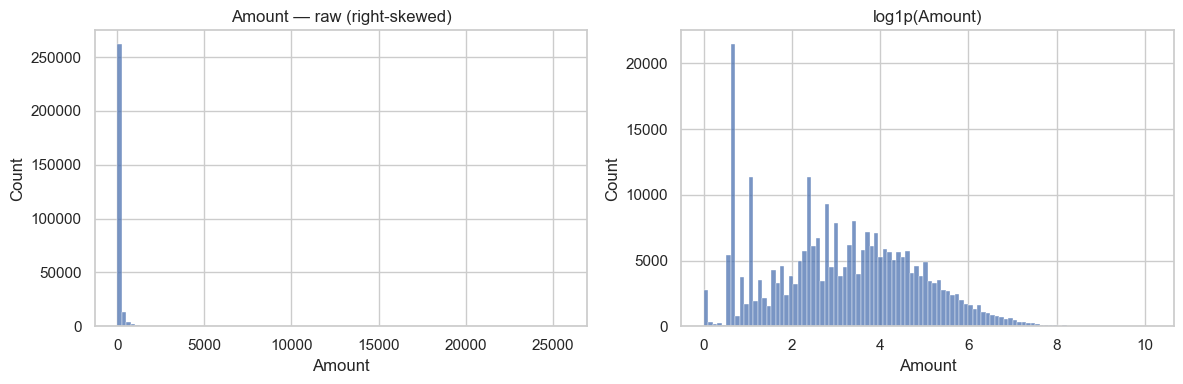

In [10]:
print(df[["Time", "Amount"]].describe())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Amount"], bins=100, ax=ax[0]).set(title="Amount — raw (right-skewed)")
sns.histplot(np.log1p(df["Amount"]), bins=100, ax=ax[1]).set(title="log1p(Amount)")
plt.tight_layout(); plt.show()

### 1.4 Class balance — the defining challenge
Headline number for the whole report.

Class
0    283253
1       473
Name: count, dtype: int64
Fraud rate: 0.167%


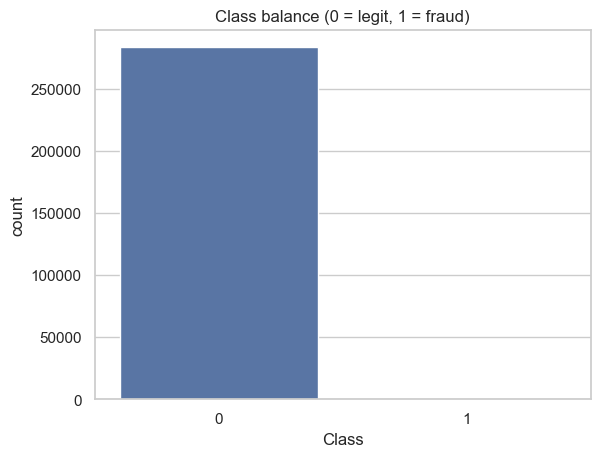

In [11]:
counts = df["Class"].value_counts()
rate = df["Class"].mean() * 100
print(counts)
print(f"Fraud rate: {rate:.3f}%")

sns.countplot(x="Class", data=df).set(title="Class balance (0 = legit, 1 = fraud)")
plt.show()

## 2. Feature engineering

### 2.1 Domain-derived features
The raw `Time` column is "seconds since the first transaction". A model can't read much
from that directly, but **hour of day** is behaviourally meaningful (fraud often clusters
at unusual hours). We also keep a log-scaled amount.

> **Encoding note:** every column here is already numeric, so there is no categorical
> encoding (one-hot / label) to do. The one ordinal feature we create (`Amount_bin`) is
> produced as integer codes. State this explicitly in your report — "no encoding required"
> is itself a justified decision.

In [12]:
df["Hour"] = (df["Time"] // 3600) % 24          # 0-23, derived from Time
df["Log_Amount"] = np.log1p(df["Amount"])        # tames right skew

# 2.2 Binning: coarse amount buckets (ordinal integer codes)
df["Amount_bin"] = pd.qcut(df["Amount"], q=5, labels=False, duplicates="drop")

df[["Time", "Hour", "Amount", "Log_Amount", "Amount_bin"]].head()

,Time,Hour,Amount,Log_Amount,Amount_bin
0,0.0000,0.0000,149.6200,5.0148,4
1,0.0000,0.0000,2.6900,1.3056,0
2,1.0000,0.0000,378.6600,5.9393,4
3,1.0000,0.0000,123.5000,4.8243,4
4,2.0000,0.0000,69.9900,4.2625,3


### 2.3 Train/test split **before** scaling (leakage guard)
We split first, then fit the scaler on the training set only. `stratify=y` preserves the
~0.17% fraud rate in both splits — essential with this much imbalance.

In [13]:
feature_cols = [c for c in df.columns if c != "Class"]
X = df[feature_cols].copy()
y = df["Class"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train fraud rate: %.3f%%" % (y_train.mean()*100))
print("Test  fraud rate: %.3f%%" % (y_test.mean()*100))

Train: (226980, 33)  Test: (56746, 33)
Train fraud rate: 0.167%
Test  fraud rate: 0.167%


### 2.4 Scaling `Time` and `Amount` (V-features are already scaled)
`V1`–`V28` came out of a PCA and are already centred/scaled, so we leave them alone.
We apply a **RobustScaler** (median/IQR based, resistant to the heavy tails) to the raw
numeric columns. The scaler is **fit on train, applied to test**.

In [14]:
to_scale = ["Time", "Amount", "Log_Amount", "Hour"]
scaler = RobustScaler()

X_train[to_scale] = scaler.fit_transform(X_train[to_scale])   # fit on TRAIN only
X_test[to_scale]  = scaler.transform(X_test[to_scale])        # transform test

X_train[to_scale].describe()

,Time,Amount,Log_Amount,Hour
count,"226,980.0000","226,980.0000","226,980.0000","226,980.0000"
mean,0.1185,0.9189,0.0070,-0.1051
std,0.5579,3.4059,0.6714,0.6477
min,-0.9964,-0.3060,-1.2724,-1.6667
25%,-0.3592,-0.2271,-0.5020,-0.5556
50%,0.0000,0.0000,0.0000,0.0000
75%,0.6408,0.7729,0.4980,0.4444
max,1.0335,272.0960,2.7351,0.8889


> **SMOTE / undersampling is intentionally NOT here.** Resampling is a *modelling*
> decision (Steps 4–5) and must happen **inside cross-validation, on training folds only**.
> Doing it now — on the whole dataset — would leak synthetic neighbours into the test set
> and is one of the most common capstone mistakes.

## 3. Applied EDA
All exploratory plots use the **training split**, so nothing we learn here is contaminated
by the test set.

In [15]:
train = X_train.copy()
train["Class"] = y_train.values

### 3.1 Which features separate fraud from legit?
Absolute correlation with the target gives a quick ranking of linear signal.

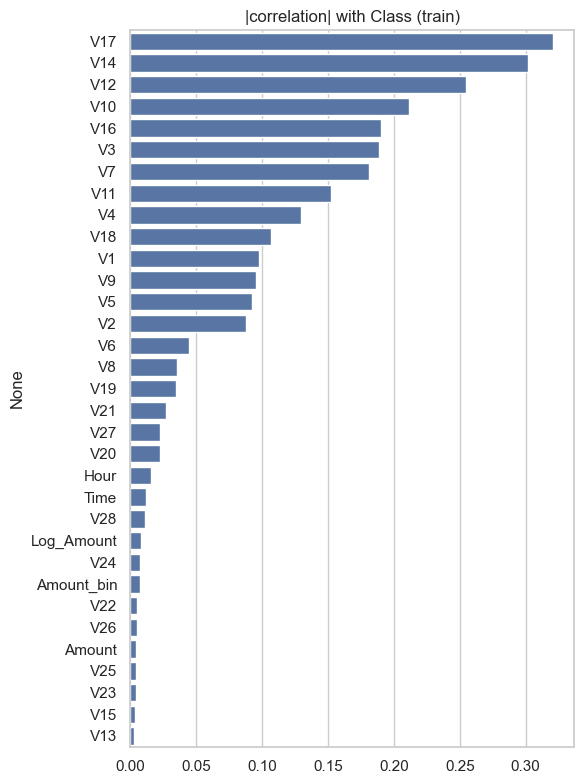

V17   0.3207
V14   0.3016
V12   0.2547
V10   0.2116
V16   0.1903
V3    0.1889
V7    0.1810
V11   0.1521
V4    0.1297
V18   0.1071
Name: Class, dtype: float64

In [16]:
corr_with_target = (train.corr(numeric_only=True)["Class"]
                    .drop("Class").abs().sort_values(ascending=False))
plt.figure(figsize=(6, 8))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index)
plt.title("|correlation| with Class (train)"); plt.tight_layout(); plt.show()
corr_with_target.head(10)

### 3.2 Distribution of the top separating features by class
Overlaid KDEs show *how* the classes differ, not just that they do.

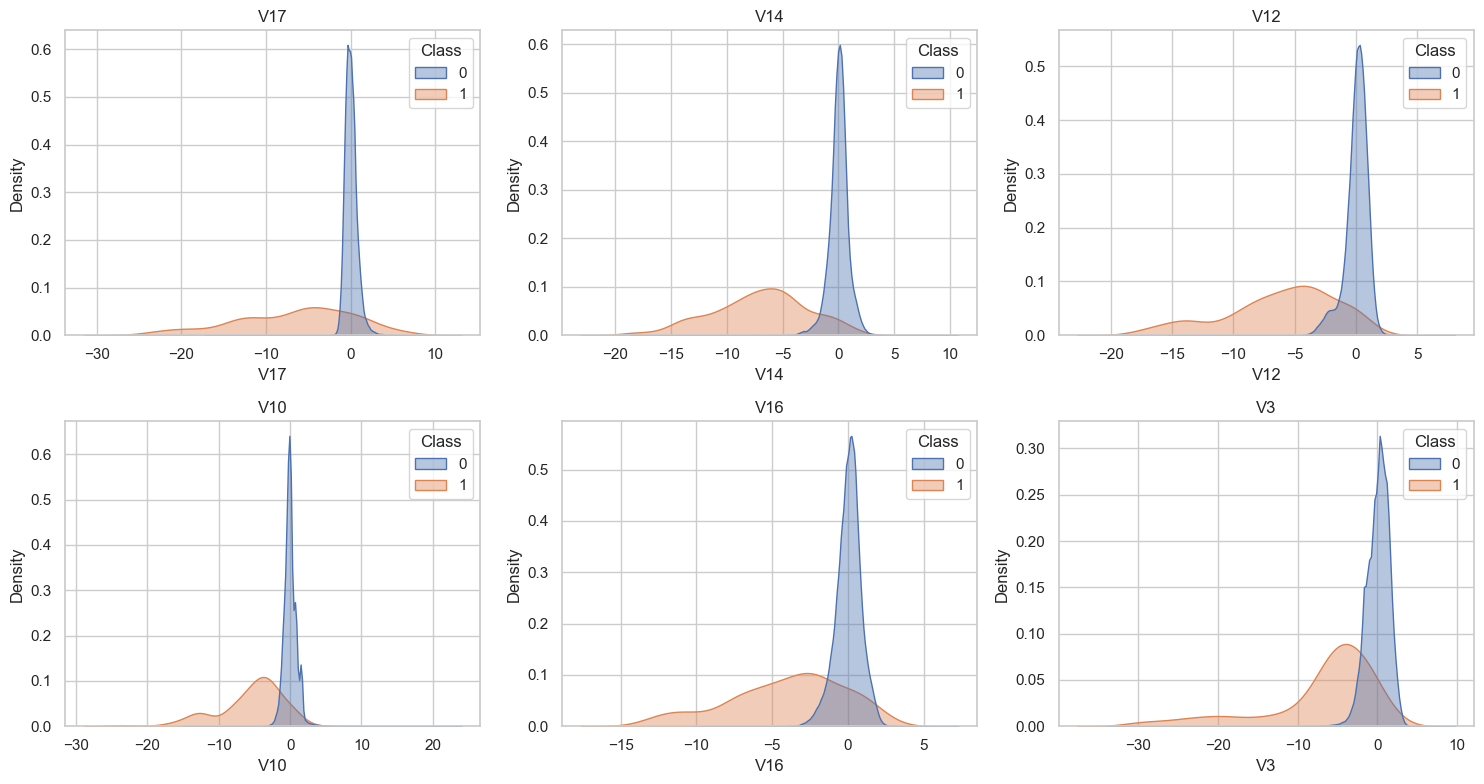

In [17]:
top_feats = corr_with_target.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.ravel(), top_feats):
    sns.kdeplot(data=train, x=feat, hue="Class", common_norm=False,
                fill=True, alpha=.4, ax=ax)
    ax.set_title(feat)
plt.tight_layout(); plt.show()

### 3.3 Amount and time-of-day behaviour
Business-readable views: do fraudulent amounts and hours differ from legitimate ones?

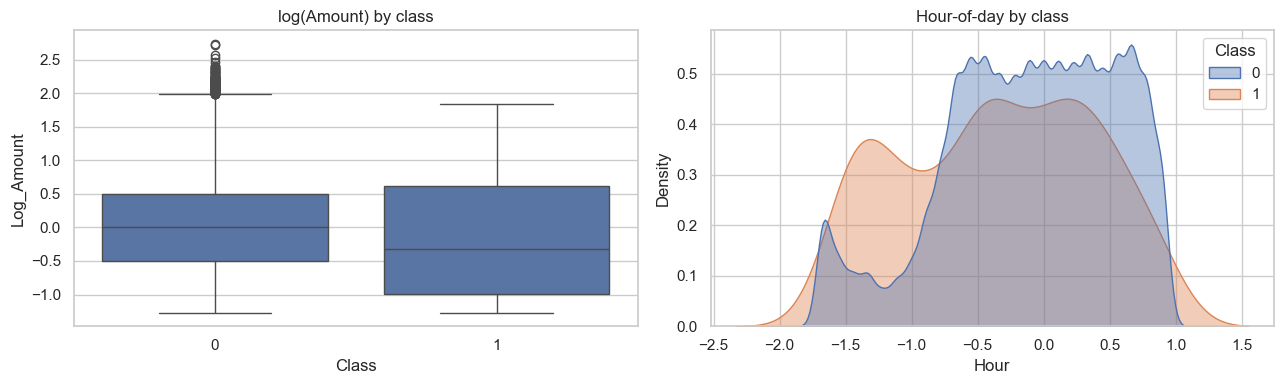

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=train, x="Class", y="Log_Amount", ax=ax[0]).set(title="log(Amount) by class")
sns.kdeplot(data=train, x="Hour", hue="Class", common_norm=False,
            fill=True, alpha=.4, ax=ax[1]).set(title="Hour-of-day by class")
plt.tight_layout(); plt.show()

## 4. Feature importance & explainability
We fit a quick tree model (fast, handles non-linearities, gives importances for free) and
then use **SHAP** for a model-agnostic, per-feature explanation. `class_weight="balanced"`
lets the model pay attention to the rare fraud class.

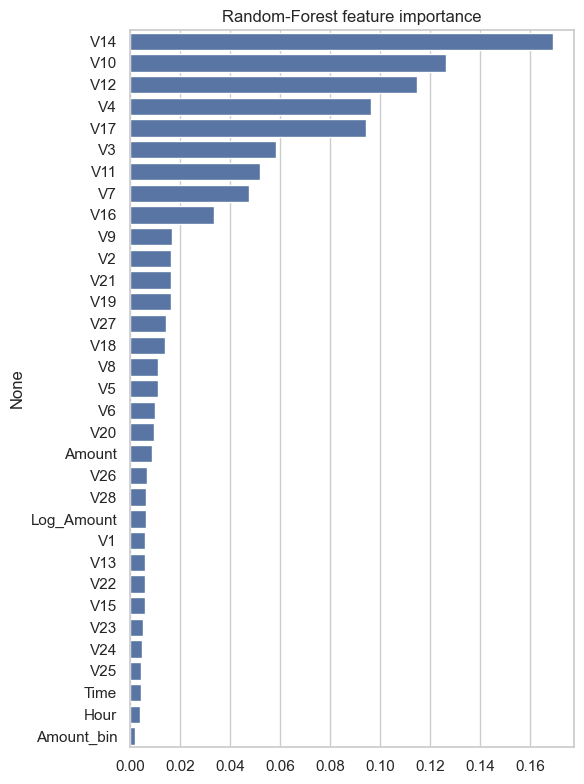

V14   0.1690
V10   0.1261
V12   0.1146
V4    0.0962
V17   0.0940
V3    0.0582
V11   0.0517
V7    0.0473
V16   0.0333
V9    0.0165
dtype: float64

In [19]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, n_jobs=-1,
    class_weight="balanced", random_state=RANDOM_STATE
)
rf.fit(X_train, y_train)

importances = (pd.Series(rf.feature_importances_, index=X_train.columns)
               .sort_values(ascending=False))
plt.figure(figsize=(6, 8))
sns.barplot(x=importances.values, y=importances.index)
plt.title("Random-Forest feature importance"); plt.tight_layout(); plt.show()
importances.head(10)

### 4.1 SHAP explainability
SHAP decomposes each prediction into per-feature contributions — far more trustworthy than
raw tree importances. Install once with `pip install shap` if needed. We sample rows to keep
it fast.

C:\Users\johan\AppData\Local\Temp\ipykernel_23820\1728001391.py:12: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, sample, show=True)


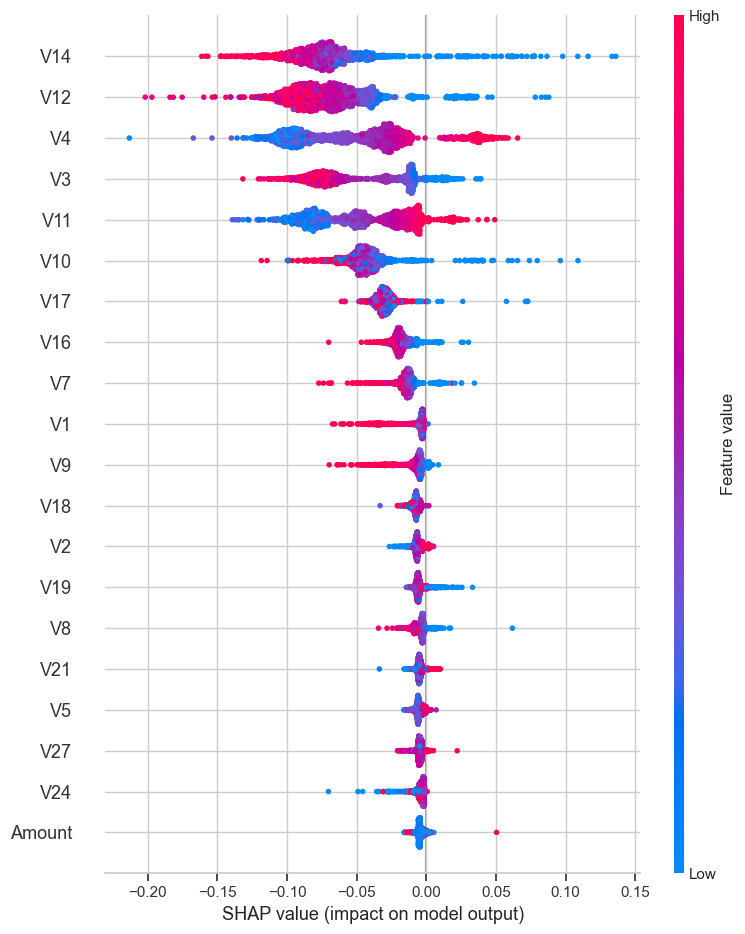

In [20]:
try:
    import shap
    sample = X_train.sample(2000, random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(sample)
    if isinstance(shap_values, list):            # older shap: [class0, class1]
        sv = shap_values[1]
    elif getattr(shap_values, "ndim", 2) == 3:   # newer shap: (rows, features, classes)
        sv = shap_values[:, :, 1]
    else:
        sv = shap_values
    shap.summary_plot(sv, sample, show=True)
except ImportError:
    print("shap not installed -> run:  pip install shap")

## 5. Feature selection
The brief asks for **at least one** approach; showing one per family demonstrates range.

- **Filter** — mutual information (captures non-linear dependence, model-free).
- **Embedded** — the Random-Forest importances from Section 4.
- **Wrapper** — Recursive Feature Elimination around logistic regression (optional; the
  most expensive, so run on a sample / smaller `k` if slow).

In [21]:
# --- Filter: mutual information (fit on train) ---
mi = pd.Series(mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE),
               index=X_train.columns).sort_values(ascending=False)
print("Top 10 by mutual information:")
print(mi.head(10))

Top 10 by mutual information:
Amount_bin   0.0117
V17          0.0080
V14          0.0079
V10          0.0073
V12          0.0073
V11          0.0066
V16          0.0059
V3           0.0047
V4           0.0046
V9           0.0041
dtype: float64


In [22]:
# --- Wrapper: RFE with logistic regression (optional / slower) ---
rfe = RFE(LogisticRegression(max_iter=1000, class_weight="balanced",
                             random_state=RANDOM_STATE),
          n_features_to_select=15)
rfe.fit(X_train, y_train)
selected = X_train.columns[rfe.support_].tolist()
print("RFE-selected features (15):")
print(selected)

RFE-selected features (15):
['Time', 'V4', 'V8', 'V10', 'V11', 'V12', 'V14', 'V15', 'V21', 'V22', 'V24', 'V25', 'V26', 'Hour', 'Log_Amount']


**How to use these:** compare the three rankings. Features that are strong across *all*
methods (commonly several `V` features plus `Log_Amount`) are safe keeps; features weak
everywhere are candidates to drop. Record your final chosen set and the reason in the report.

## 6. Dimensionality reduction

### 6.1 PCA
Because `V1`–`V28` are *already* principal components, PCA here is largely a formality — but
the variance curve is still worth showing, and it is a required technique.

Components to retain 95% variance: 23


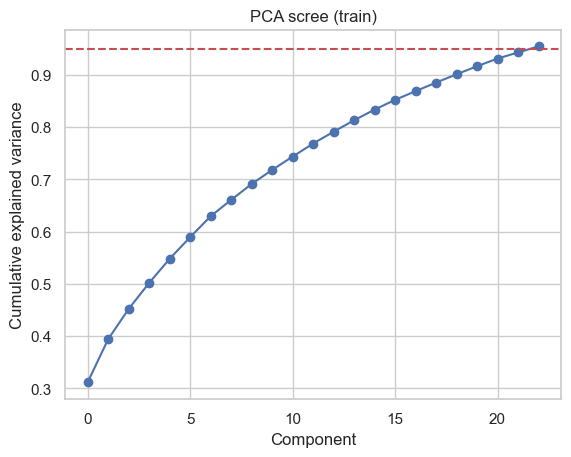

In [23]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)   # keep 95% variance
pca.fit(X_train)
print("Components to retain 95% variance:", pca.n_components_)

plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.axhline(0.95, ls="--", c="r")
plt.xlabel("Component"); plt.ylabel("Cumulative explained variance")
plt.title("PCA scree (train)"); plt.show()

### 6.2 t-SNE — 2-D visualisation
t-SNE is slow and memory-hungry, so we run it on a **balanced sample** (all fraud + an equal
slice of legit). This is a *visualisation only* — never feed t-SNE coordinates into the model.
Swap in UMAP (`pip install umap-learn`) if you prefer; it is faster on large data.

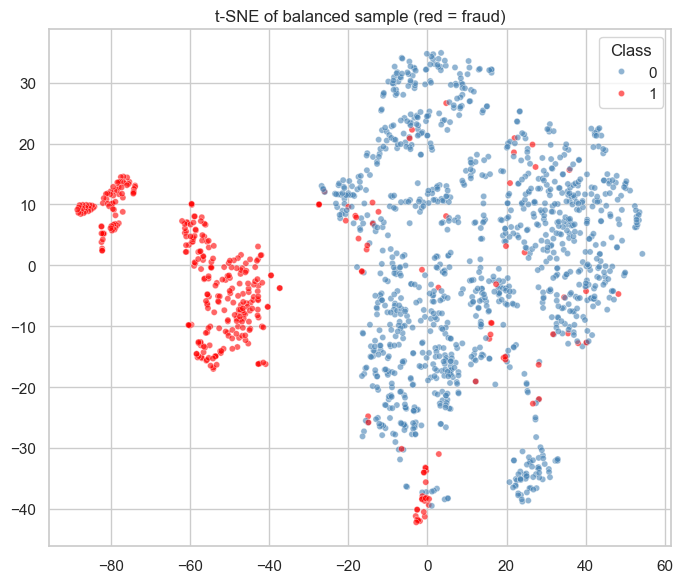

In [24]:
fraud_idx = y_train[y_train == 1].index
legit_idx = y_train[y_train == 0].sample(len(fraud_idx)*3, random_state=RANDOM_STATE).index
sample_idx = fraud_idx.union(legit_idx)

X_vis = X_train.loc[sample_idx]
y_vis = y_train.loc[sample_idx]

emb = TSNE(n_components=2, perplexity=30, init="pca",
           random_state=RANDOM_STATE).fit_transform(X_vis)

plt.figure(figsize=(7, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=y_vis.values,
                palette={0: "steelblue", 1: "red"}, alpha=.6, s=20)
plt.title("t-SNE of balanced sample (red = fraud)")
plt.legend(title="Class"); plt.tight_layout(); plt.show()